In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
# import the iris dataset
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn import metrics
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.neural_network import MLPClassifier

In [2]:
iris = load_iris()
# data, target_names, target, feature_names
print(iris.target_names)  # try print(iris.data), print(iris.feature_names), etc.

['setosa' 'versicolor' 'virginica']


In [3]:
# Feature matrix in a object named X
X = iris.data
# response vector in a object named y
y = iris.target

print(np.shape(X))
print(np.shape(y))

(150, 4)
(150,)


In [4]:
# Split iris data in train and test data (80:20)
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=4)

**Feature Scaling**

Before making actual predictions, it is always a good practice to scale the features so that all of them can be uniformly evaluated. Feature scaling is performed only on the training data and not on test data. This is because in real world, data is not scaled and the ultimate purpose of the neural network is to make predictions on real world data. Therefore, we try to keep our test data as real as possible.

In [5]:
# scale the training data
scaler = StandardScaler()
scaler.fit(X_train)

X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

In [6]:
# now build the neural network using MLPClassifier
# MLPClassifier stands for Multi-layer Perceptron classifier

# https://analyticsindiamag.com/a-beginners-guide-to-scikit-learns-mlpclassifier/

# the following code will create a classifier with three layers of 10 nodes each
# max_iter refers to the number of epochs, one epoch is a combination of one cycle of 
# feed-forward and back propagation phase.
mlp = MLPClassifier(hidden_layer_sizes=(10, 10, 10), max_iter=1000)

# now fit the classifer to the training data
mlp.fit(X_train, y_train)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(10, ...)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",1000
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",None


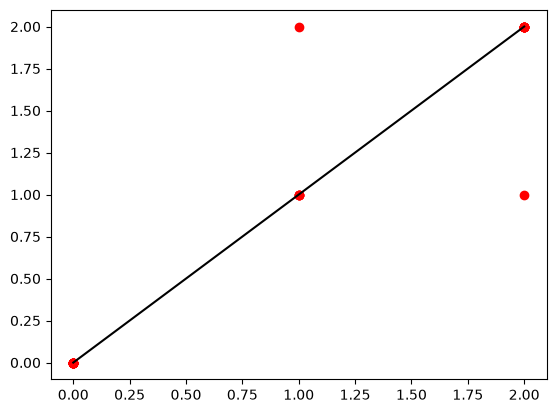

In [7]:
# try making some predictions using your classifier
predictions = mlp.predict(X_test)

plt.plot(y_test, predictions, 'ro')
plt.plot([0, 2], [0, 2],'k')

In [8]:
# and now look at the accuracy of your predictions
print(confusion_matrix(y_test,predictions)) # Confusion Matrix

# We will use the confusion matrix to determine the accuracy which is measured as the total 
# number of correct predictions divided by the total number of predictions.

[[16  0  0]
 [ 0  4  1]
 [ 0  1  8]]


In [9]:
# look at the accuracy of your predictions
print(classification_report(y_test,predictions)) # Classification Report

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        16
           1       0.80      0.80      0.80         5
           2       0.89      0.89      0.89         9

    accuracy                           0.93        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.93      0.93      0.93        30



In [11]:
# now build a loop to test how well different number of hidden layers performs
scores = {}
scores_list = []
l_range = range(4, 20, 1)
# the loop variable l below will iterate through the integers from 4 to 19 
# (range(4, 20, 1)).
# This defines 3 hidden layers in the network
# All 3 layers are assigned the same number of neurons (l) in every iteration.
# Iteration 1 (l = 4): 3 hidden layers with 4 neurons each 
# Iteration 2 (l = 5): 3 hidden layers with 5 neurons each 
# ...
# Final Iteration (l = 19): 3 hidden layers with 19 neurons each

for l in l_range:
    print(l)
    mlp = MLPClassifier(hidden_layer_sizes=(l, l, l), max_iter=5000)  # do we need to change anything here???
    mlp.fit(X_train, y_train)
    y_pred = mlp.predict(X_test)
    scores[l] = metrics.accuracy_score(y_test,y_pred)
    scores_list.append(metrics.accuracy_score(y_test,y_pred))

4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19


Text(0, 0.5, 'accuracy score')

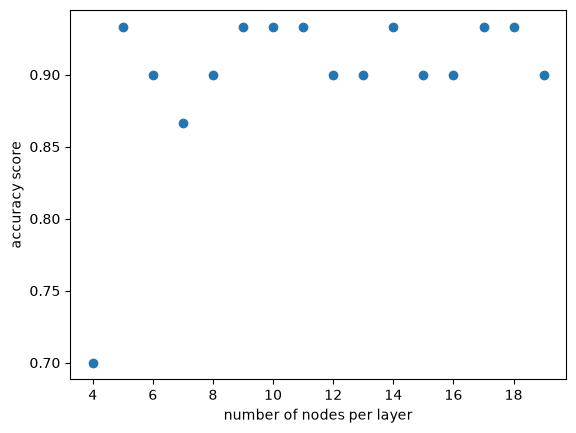

In [16]:
# plot the model accuracy for each value of k
plt.scatter(l_range,scores_list)
plt.xlabel('number of nodes per layer')
plt.ylabel('accuracy score')

In [13]:
# let's go with a 3 layer with 9 nodes in each layer
mlp = MLPClassifier(hidden_layer_sizes=(9,9,9), max_iter=1000)
mlp.fit(X_train, y_train)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(9, ...)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",1000
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",None


In [14]:
# here we apply the new model built above to 'new' data

#0 = setosa, 1=versicolor, 2=virginica
classes = {0:'setosa',1:'versicolor',2:'virginica'}

# Make a prediction for the 'new' data 
# predict for the below two random observations
x_new = [[3,4,5,2],[5,4,2,2]]
x_new_scaled = scaler.transform(x_new)

y_predict = mlp.predict(x_new_scaled)

# Is this what we get with the K-Nearest-Neighbors Classifier?
print(classes[y_predict[0]]) # y_predict[0] made a prediction. Executing classes[1] returns what class it thinks this iris is.
print(classes[y_predict[1]]) # y_predict[1] made a prediction.. Executing classes[0] returns what class it thinks this iris is.

versicolor
versicolor


Text(0.5, 0, 'sepal width (cm)')

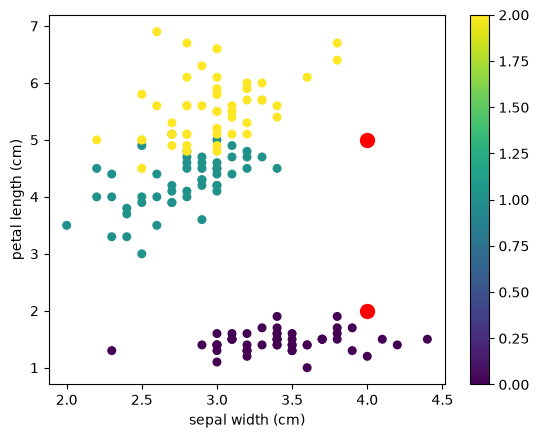

In [15]:
plt.scatter(iris.data[:,1], iris.data[:,2], s = 30, c = iris.target)
plt.colorbar()
plt.plot(np.array(x_new)[:,1], np.array(x_new)[:,2], 'or', markersize = 10)

plt.ylabel(iris.feature_names[2])
plt.xlabel(iris.feature_names[1])